# Advent of Code 2025 - Day 9

## Imports

In [ ]:
import base64
import warnings

import marimo as mo
import plotly.graph_objects as go

from collections import namedtuple

from aoc.utils import read_data

## Day 9 - Movie Theater

### Part 1 - Instructions

You slide down the firepole in the corner of the playground and land in the North Pole base movie theater!

The movie theater has a big tile floor with an interesting pattern. Elves here are redecorating the theater by switching out some of the square tiles in the big grid they form. Some of the tiles are red; the Elves would like to find the largest rectangle that uses red tiles for two of its opposite corners. They even have a list of where the red tiles are located in the grid (your puzzle input).

For example:

```
7,1
11,1
11,7
9,7
9,5
2,5
2,3
7,3
```

Showing red tiles as # and other tiles as ., the above arrangement of red tiles would look like this:

```
..............
.......#...#..
..............
..#....#......
..............
..#......#....
..............
.........#.#..
..............
```

You can choose any two red tiles as the opposite corners of your rectangle; your goal is to find the largest rectangle possible.

For example, you could make a rectangle (shown as O) with an area of 24 between 2,5 and 9,7:

```
..............
.......#...#..
..............
..#....#......
..............
..OOOOOOOO....
..OOOOOOOO....
..OOOOOOOO.#..
..............
```

Or, you could make a rectangle with area 35 between 7,1 and 11,7:

```
..............
.......OOOOO..
.......OOOOO..
..#....OOOOO..
.......OOOOO..
..#....OOOOO..
.......OOOOO..
.......OOOOO..
..............
```

You could even make a thin rectangle with an area of only 6 between 7,3 and 2,3:

```
..............
.......#...#..
..............
..OOOOOO......
..............
..#......#....
..............
.........#.#..
..............
```

Ultimately, the largest rectangle you can make in this example has area 50. One way to do this is between 2,5 and 11,1:

```
..............
..OOOOOOOOOO..
..OOOOOOOOOO..
..OOOOOOOOOO..
..OOOOOOOOOO..
..OOOOOOOOOO..
..............
.........#.#..
..............
```

Using two red tiles as opposite corners, what is the largest area of any rectangle you can make?

### Part 1 - Solution

In [ ]:
def plot_red_tiles(
    red_tile_coordinates: list[list[int]],
    largest_rect_coordinates: list[list[int]],
    line_color: str="black",
    marker_color: str="black",
) -> None:
    """
    Plot connected tile coordinates and a largest rectangle overlay.

    This function visualizes two closed polygonal paths using Plotly:
    one representing red tiles and another representing the largest
    rectangle. Both shapes are plotted with equal x/y scaling.

    Args:
        red_tile_coordinates: List of [x, y] pairs defining red tiles.
        largest_rect_coordinates: List of [x, y] pairs defining a rectangle.
        line_color: Line color for the red tile connections.
        marker_color: Marker color for the red tile points.
    """

    def plot_connections(
        fig: go.Figure,  # pyright: ignore[reportInvalidTypeForm]
        coordinates: list[list[int]],
        line_color: str,
        marker_color: str,
    ) -> go.Figure:  # pyright: ignore[reportInvalidTypeForm]
        """
        Add a closed polygon trace to an existing Plotly figure.

        The first coordinate is appended to the end to close the loop.
        A single scatter trace with markers and lines is added.

        Args:
            fig: Plotly figure to which the trace is added.
            coordinates: List of [x, y] coordinate pairs.
            line_color: Color of the connecting lines.
            marker_color: Color of the markers.

        Returns:
            The updated Plotly figure.
        """
        coordinates.append(coordinates[0])
        x_coordinates, y_coordinates = zip(*coordinates)

        fig.add_trace(go.Scatter(
            x=x_coordinates,
            y=y_coordinates,
            mode="markers+lines",
            line=dict(color=line_color),
            marker=dict(color=marker_color),
        ))

        return fig

    fig = go.Figure()

    fig = plot_connections(fig, red_tile_coordinates, line_color, marker_color)
    fig = plot_connections(fig, largest_rect_coordinates, "red", "red")

    fig.update_layout(
        yaxis_scaleanchor="x",
        template="plotly_white",
    )

    return fig

In [ ]:
def exercise_9_1_find_largest_rectangle(
    red_tile_data: list[str],
) -> tuple[int, list[list[int]] | None]:
    """
    Find the largest possible rectangle area formed by any two red tiles as opposite corners.

    Each coordinate is given as a string "x,y". Two tiles define a rectangle whose area is
    computed as (abs(x1 - x2) + 1) * (abs(y1 - y2) + 1). All unique tile pairs are evaluated,
    and the largest resulting rectangle area is returned.

    Args:
        red_tile_data (list[str]): List of red tile positions as "x,y" strings.

    Returns:
        tuple[int, list[list[int]] | None]: The largest rectangle area formed
            by any pair of red tiles, and the corner coordinates of that rectangle.
    """
    red_tile_coordinates = [
        [int(num) for num in row.split(",")] for row in red_tile_data
    ]

    largest_rect_area = 0
    largest_rect_coordinates = None

    for i in range(len(red_tile_coordinates)):
        for j in range(i):
            c1 = red_tile_coordinates[i]
            c2 = red_tile_coordinates[j]

            rectangle_area = (1 + abs(c1[0]-c2[0])) * (1 + abs(c1[1]-c2[1]))

            if rectangle_area > largest_rect_area:
                largest_rect_area = rectangle_area


                largest_rect_coordinates = [c1, c2]
                largest_rect_coordinates.insert(1, [c2[0], c1[1]])
                largest_rect_coordinates.append([c1[0], c2[1]])

    return largest_rect_area, largest_rect_coordinates

In [ ]:
example_red_tile_data = [
    "7,1",
    "11,1",
    "11,7",
    "9,7",
    "9,5",
    "2,5",
    "2,3",
    "7,3",
]

solution_example_9_1, _ = exercise_9_1_find_largest_rectangle(red_tile_data=example_red_tile_data)

assert solution_example_9_1 == 50

In [ ]:
red_tile_data = read_data(file_path="data/2025/2025_day_09.txt", separator="\n")

solution_9_1, largest_rect_coordinates_9_1 = exercise_9_1_find_largest_rectangle(red_tile_data=red_tile_data)

assert solution_9_1 == 4738108384

In [ ]:
red_tile_coordinates_9_1 = [[int(num) for num in row.split(",")] for row in red_tile_data]

figure_9_1 = plot_red_tiles(
    red_tile_coordinates=red_tile_coordinates_9_1,
    largest_rect_coordinates=largest_rect_coordinates_9_1,
)

mo.accordion({"Interactive plot": figure_9_1})  # pyright: ignore[reportUnusedExpression]

<marimo-plotly data-figure='{"data":[{"line":{"color":"black"},"marker":{"color":"black"},"mode":"markers+lines","x":[98220,98220,98394,98394,97964,97964,97594,97594,97608,97608,97863,97863,96897,96897,97062,97062,96526,96526,96191,96191,96290,96290,95913,95913,95698,95698,95293,95293,94828,94828,94220,94220,94313,94313,93002,93002,93196,93196,92443,92443,91489,91489,91500,91500,90784,90784,89523,89523,88995,88995,88574,88574,87681,87681,87167,87167,86461,86461,85544,85544,84196,84196,83908,83908,82685,82685,81777,81777,80934,80934,80299,80299,79199,79199,77832,77832,77357,77357,76228,76228,74839,74839,73998,73998,73047,73047,71743,71743,70891,70891,69711,69711,68439,68439,67387,67387,66308,66308,65196,65196,63880,63880,62858,62858,61711,61711,60415,60415,59305,59305,58173,58173,56890,56890,55730,55730,54520,54520,53254,53254,52070,52070,50831,50831,49619,49619,48394,48394,47180,47180,46015,46015,44764,44764,43614,43614,42413,42413,41201,41201,40026,40026,38780,38780,37674,37674,36427,36427,35180,35180,34076,34076,32912,32912,31874,31874,30646,30646,29738,29738,28597,28597,27459,27459,26526,26526,25507,25507,24479,24479,23183,23183,22267,22267,21052,21052,20033,20033,19440,19440,18559,18559,17730,17730,16418,16418,15611,15611,15186,15186,14428,14428,13295,13295,12713,12713,12005,12005,11033,11033,10428,10428,9804,9804,8963,8963,8298,8298,7984,7984,6881,6881,6968,6968,6351,6351,5780,5780,5556,5556,4525,4525,4416,4416,3819,3819,3641,3641,3821,3821,3630,3630,3291,3291,2640,2640,2523,2523,2253,2253,2492,2492,1859,1859,2127,2127,2506,2506,94654,94654,1753,1753,1649,1649,2365,2365,2728,2728,2476,2476,2205,2205,3084,3084,3171,3171,3773,3773,3147,3147,3584,3584,3979,3979,4424,4424,5490,5490,5306,5306,5866,5866,6316,6316,7033,7033,7674,7674,7856,7856,8631,8631,9547,9547,10352,10352,11057,11057,11363,11363,12471,12471,13401,13401,14113,14113,14428,14428,15682,15682,16487,16487,17453,17453,18211,18211,19216,19216,20204,20204,20784,20784,21899,21899,22677,22677,24129,24129,24874,24874,26124,26124,27207,27207,28294,28294,29257,29257,30295,30295,31293,31293,32641,32641,33770,33770,34947,34947,36107,36107,37058,37058,38366,38366,39626,39626,40661,40661,41929,41929,43040,43040,44270,44270,45498,45498,46740,46740,47961,47961,49161,49161,50383,50383,51596,51596,52836,52836,54012,54012,55249,55249,56482,56482,57580,57580,58848,58848,59965,59965,61202,61202,62386,62386,63500,63500,64646,64646,66026,66026,67167,67167,68100,68100,69437,69437,70528,70528,71697,71697,72570,72570,73543,73543,74597,74597,75796,75796,76572,76572,78015,78015,78678,78678,79713,79713,80395,80395,81280,81280,82315,82315,83031,83031,84563,84563,85020,85020,86028,86028,86465,86465,87597,87597,88249,88249,89182,89182,89218,89218,90604,90604,90856,90856,91183,91183,92131,92131,92807,92807,92842,92842,93343,93343,94141,94141,94960,94960,95258,95258,95794,95794,95832,95832,96396,96396,97009,97009,96927,96927,97123,97123,97488,97488,97947,97947,97407,97407,97334,97334,97943,97943,98268,98268,98313,98313,98220],"y":[50383,51611,51611,52815,52815,54005,54005,55224,55224,56483,56483,57566,57566,58822,58822,59947,59947,61107,61107,62379,62379,63533,63533,64738,64738,65885,65885,67009,67009,68073,68073,69435,69435,70174,70174,71616,71616,72602,72602,73462,73462,74876,74876,75874,75874,76501,76501,77604,77604,78801,78801,79650,79650,80801,80801,81809,81809,82630,82630,83027,83027,84452,84452,84937,84937,85741,85741,86619,86619,87768,87768,88349,88349,88541,88541,89980,89980,90494,90494,90566,90566,91519,91519,92314,92314,92444,92444,93461,93461,93816,93816,93931,93931,94554,94554,95135,95135,95641,95641,95506,95506,96329,96329,96763,96763,96562,96562,97182,97182,97788,97788,97501,97501,98040,98040,98269,98269,97753,97753,98440,98440,97834,97834,97766,97766,98209,98209,98038,98038,97341,97341,97712,97712,97144,97144,97019,97019,96935,96935,96646,96646,96658,96658,96087,96087,96044,96044,95949,95949,95401,95401,95034,95034,94348,94348,94127,94127,93188,93188,92766,92766,92326,92326,91509,

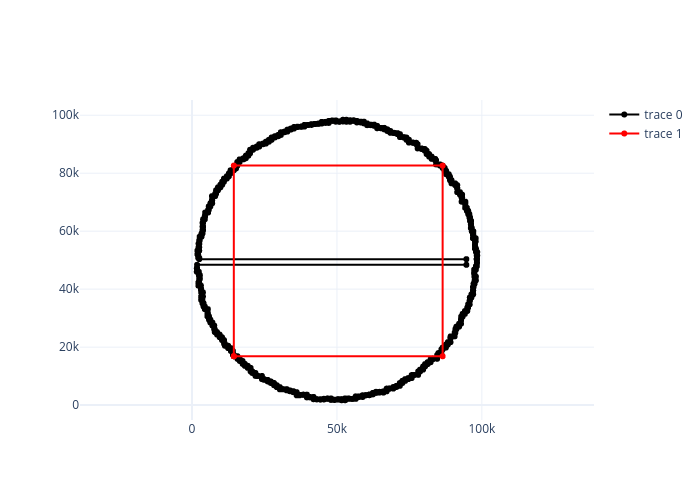

In [ ]:
# Kaleido 0.2.1 (pinned, as kaleido 1.x needs Chrome) raises a deprecation warning here.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    figure_png_9_1 = figure_9_1.to_image(format="png")

encoded_figure_9_1 = base64.b64encode(figure_png_9_1).decode()

mo.md(f"![Largest rectangle](data:image/png;base64,{encoded_figure_9_1})")

### Part 2 - Instructions

The Elves just remembered: they can only switch out tiles that are red or green. So, your rectangle can only include red or green tiles.

In your list, every red tile is connected to the red tile before and after it by a straight line of green tiles. The list wraps, so the first red tile is also connected to the last red tile. Tiles that are adjacent in your list will always be on either the same row or the same column.

Using the same example as before, the tiles marked X would be green:

```
..............
.......#XXX#..
.......X...X..
..#XXXX#...X..
..X........X..
..#XXXXXX#.X..
.........X.X..
.........#X#..
..............
```

In addition, all of the tiles inside this loop of red and green tiles are also green. So, in this example, these are the green tiles:

```
..............
.......#XXX#..
.......XXXXX..
..#XXXX#XXXX..
..XXXXXXXXXX..
..#XXXXXX#XX..
.........XXX..
.........#X#..
..............
```

The remaining tiles are never red nor green.

The rectangle you choose still must have red tiles in opposite corners, but any other tiles it includes must now be red or green. This significantly limits your options.

For example, you could make a rectangle out of red and green tiles with an area of 15 between 7,3 and 11,1:

```
..............
.......OOOOO..
.......OOOOO..
..#XXXXOOOOO..
..XXXXXXXXXX..
..#XXXXXX#XX..
.........XXX..
.........#X#..
..............
```

Or, you could make a thin rectangle with an area of 3 between 9,7 and 9,5:

```
..............
.......#XXX#..
.......XXXXX..
..#XXXX#XXXX..
..XXXXXXXXXX..
..#XXXXXXOXX..
.........OXX..
.........OX#..
..............
```

The largest rectangle you can make in this example using only red and green tiles has area 24. One way to do this is between 9,5 and 2,3:

```
..............
.......#XXX#..
.......XXXXX..
..OOOOOOOOXX..
..OOOOOOOOXX..
..OOOOOOOOXX..
.........XXX..
.........#X#..
..............
```

Using two red tiles as opposite corners, what is the largest area of any rectangle you can make using only red and green tiles?

### Part 2 - Solution

In [ ]:
def exercise_9_2_find_largest_area(
    red_tile_data: list[str],
    number_of_sampled_edge_points: int
) -> tuple[int, list[list[int]] | None]:
    """
    Find the largest axis-aligned rectangle using only red and green tiles.

    Red tiles form the vertices of a closed, orthogonal loop. Consecutive
    red tiles are connected by straight lines of green tiles, and all tiles
    inside this loop are also green. The loop defines a simple orthogonal
    polygon without holes.

    The rectangle must use two red tiles as opposite corners. All tiles
    inside the rectangle, including its boundary, must lie entirely within
    the red-green region defined by the polygon.

    The core geometric insight is:
    - A point is inside if it is bounded on all sides.

    For each candidate rectangle, only points on the rectangle boundary
    are tested. If every sampled boundary point is bounded on all four
    cardinal directions by polygon edges, the rectangle is guaranteed to
    lie fully inside the allowed region.

    Early pruning is applied to discard rectangle candidates whose area
    cannot exceed the current maximum.

    Args:
        red_tile_coordinates (list[str]):
            Ordered list of red tile coordinates as "x,y" strings. Adjacent
            entries are connected by straight horizontal or vertical paths.
        number_of_sampled_edge_points (int): Number of points to sample on 
            the rectangle edges, includes the corner points, so the minimum
            value for this variable is 2.

    Returns:
        tuple[int, list[list[int]] | None]:
            The largest rectangle area that can be formed using only red
            and green tiles, and the corner coordinates of that rectangle.
    """
    Point = namedtuple("Point", ["x", "y"])

    # Get data in appropriate format.
    red_tile_coordinates = [
        Point(*[int(num) for num in row.split(",")])
        for row in red_tile_data
    ]

    # Build edges (normalized)
    horizontal_edges = []
    vertical_edges = []

    for current, next in zip(red_tile_coordinates, red_tile_coordinates[1:] + red_tile_coordinates[:1]):
        if current.y == next.y:
            horizontal_edges.append((current.y, (min(current.x, next.x), max(current.x, next.x))))
        elif current.x == next.x:
            vertical_edges.append((current.x, (min(current.y, next.y), max(current.y, next.y))))

    horizontal_edges.sort()
    vertical_edges.sort()

    def is_surrounded(
        corner: Point,  # pyright: ignore[reportInvalidTypeForm]
        horizontal_edges: list[tuple[int, tuple[int, int]]] = horizontal_edges,
        vertical_edges: list[tuple[int, tuple[int, int]]] = vertical_edges,
    ) -> bool:
        """
        Determine whether a point lies inside the red-green polygon.

        The polygon is represented implicitly by horizontal and vertical edges.
        A point is considered inside (or on the boundary) if it is blocked by
        at least one polygon edge in all four cardinal directions.

        This function checks for:
        - A vertical edge to the left
        - A vertical edge to the right
        - A horizontal edge below
        - A horizontal edge above

        The defining principle is:
        A point is inside if it is bounded on all sides.

        This test is a specialized ray-casting variant optimized for simple
        orthogonal polygons without holes.

        Args:
            corner (Point):
                The point to test for containment.
            horizontal_edges (list[tuple[int, tuple[int, int]]]):
                Horizontal polygon edges as (y, (x_min, x_max)).
            vertical_edges (list[tuple[int, tuple[int, int]]]):
                Vertical polygon edges as (x, (y_min, y_max)).

        Returns:
            bool:
                True if the point is inside or on the boundary of the polygon,
                False otherwise.
        """
        horizontal_left = False
        horizontal_right = False
        vertical_down = False
        vertical_up = False

        for _, (low, high) in (
            (k, v) for k, v in vertical_edges if k <= corner.x
        ):
            if low <= corner.y <= high:
                horizontal_left = True
                break

        for _, (low, high) in (
            (k, v) for k, v in vertical_edges if k >= corner.x
        ):
            if low <= corner.y <= high:
                horizontal_right = True
                break

        for _, (low, high) in (
            (k, v) for k, v in horizontal_edges if k <= corner.y
        ):
            if low <= corner.x <= high:
                vertical_down = True
                break

        for _, (low, high) in (
            (k, v) for k, v in horizontal_edges if k >= corner.y
        ):
            if low <= corner.x <= high:
                vertical_up = True
                break

        return (
            horizontal_left
            and horizontal_right
            and vertical_down
            and vertical_up
        )

    def interpolate_edge_points(
        start_coordinate: int,
        end_coordinate: int,
        number_of_interpolated_points: int,
    ) -> list[int]:
        """
        Construct integer sample points along a rectangle edge by interpolation.

        Args:
            start_coordinate (int): Start coordinate.
            end_coordinate (int): End coordinate.
            number_of_interpolated_points (int): Number of points to sample along the 
                edge (must be >= 2).

        Returns:
            list[int]: Integer coordinates sampled between the start and end values, 
                inclusive.
        """
        assert number_of_interpolated_points >= 2, ("number_of_interpolated_points must be at least 2")

        if number_of_interpolated_points == 2:
            return [start_coordinate, end_coordinate]

        step = (end_coordinate - start_coordinate) / (number_of_interpolated_points - 1)
        interpolated_coordinates = [round(start_coordinate + i * step) for i in range(number_of_interpolated_points)]

        return interpolated_coordinates

    largest_rect_area = 0
    largest_rect_coordinates = None

    # Main loop
    for i in range(len(red_tile_coordinates)):
        for j in range(i):
            c1 = red_tile_coordinates[i]
            c3 = red_tile_coordinates[j]

            if c1.x != c3.x and c1.y != c3.y:
                width = 1 + abs(c1.x - c3.x)
                height = 1 + abs(c1.y - c3.y)
                rectangle_area = width * height

                # Early pruning
                if rectangle_area <= largest_rect_area:
                    continue

                c4 = Point(x=c1.x, y=c3.y)
                c2 = Point(x=c3.x, y=c1.y)

                xs = interpolate_edge_points(c1.x, c3.x, number_of_sampled_edge_points)
                ys = interpolate_edge_points(c1.y, c3.y, number_of_sampled_edge_points)

                test_points = []

                for x in xs:
                    test_points.append(Point(x, c1.y))
                    test_points.append(Point(x, c3.y))

                for y in ys:
                    test_points.append(Point(c1.x, y))
                    test_points.append(Point(c3.x, y))

                if all(is_surrounded(p) for p in test_points):
                    largest_rect_area = rectangle_area
                    largest_rect_coordinates = [c1, c4, c3, c2]

    return largest_rect_area, largest_rect_coordinates

In [ ]:
solution_example_9_2, _ = exercise_9_2_find_largest_area(
    red_tile_data=example_red_tile_data,
    number_of_sampled_edge_points=2
)

assert solution_example_9_2 == 24

In [ ]:
# Empirically determined that 44 is the first integer that produces the correct answer.
# Takes about 40 seconds to retrieve the result.
# Replacing the sampling method with a more sophisticated method that does not perform
# duplicate computations will significantly improve the computation time.
number_of_sampled_edge_points = 44

solution_9_2, largest_rect_coordinates_9_2 = exercise_9_2_find_largest_area(
    red_tile_data=red_tile_data,
    number_of_sampled_edge_points=number_of_sampled_edge_points
)

assert solution_9_2 == 1513792010

In [ ]:
red_tile_coordinates_9_2 = [[int(num) for num in row.split(",")] for row in red_tile_data]

figure_9_2 = plot_red_tiles(
    red_tile_coordinates=red_tile_coordinates_9_2,
    largest_rect_coordinates=largest_rect_coordinates_9_2,
)

mo.accordion({"Interactive plot": figure_9_2})  # pyright: ignore[reportUnusedExpression]

<marimo-plotly data-figure='{"data":[{"line":{"color":"black"},"marker":{"color":"black"},"mode":"markers+lines","x":[98220,98220,98394,98394,97964,97964,97594,97594,97608,97608,97863,97863,96897,96897,97062,97062,96526,96526,96191,96191,96290,96290,95913,95913,95698,95698,95293,95293,94828,94828,94220,94220,94313,94313,93002,93002,93196,93196,92443,92443,91489,91489,91500,91500,90784,90784,89523,89523,88995,88995,88574,88574,87681,87681,87167,87167,86461,86461,85544,85544,84196,84196,83908,83908,82685,82685,81777,81777,80934,80934,80299,80299,79199,79199,77832,77832,77357,77357,76228,76228,74839,74839,73998,73998,73047,73047,71743,71743,70891,70891,69711,69711,68439,68439,67387,67387,66308,66308,65196,65196,63880,63880,62858,62858,61711,61711,60415,60415,59305,59305,58173,58173,56890,56890,55730,55730,54520,54520,53254,53254,52070,52070,50831,50831,49619,49619,48394,48394,47180,47180,46015,46015,44764,44764,43614,43614,42413,42413,41201,41201,40026,40026,38780,38780,37674,37674,36427,36427,35180,35180,34076,34076,32912,32912,31874,31874,30646,30646,29738,29738,28597,28597,27459,27459,26526,26526,25507,25507,24479,24479,23183,23183,22267,22267,21052,21052,20033,20033,19440,19440,18559,18559,17730,17730,16418,16418,15611,15611,15186,15186,14428,14428,13295,13295,12713,12713,12005,12005,11033,11033,10428,10428,9804,9804,8963,8963,8298,8298,7984,7984,6881,6881,6968,6968,6351,6351,5780,5780,5556,5556,4525,4525,4416,4416,3819,3819,3641,3641,3821,3821,3630,3630,3291,3291,2640,2640,2523,2523,2253,2253,2492,2492,1859,1859,2127,2127,2506,2506,94654,94654,1753,1753,1649,1649,2365,2365,2728,2728,2476,2476,2205,2205,3084,3084,3171,3171,3773,3773,3147,3147,3584,3584,3979,3979,4424,4424,5490,5490,5306,5306,5866,5866,6316,6316,7033,7033,7674,7674,7856,7856,8631,8631,9547,9547,10352,10352,11057,11057,11363,11363,12471,12471,13401,13401,14113,14113,14428,14428,15682,15682,16487,16487,17453,17453,18211,18211,19216,19216,20204,20204,20784,20784,21899,21899,22677,22677,24129,24129,24874,24874,26124,26124,27207,27207,28294,28294,29257,29257,30295,30295,31293,31293,32641,32641,33770,33770,34947,34947,36107,36107,37058,37058,38366,38366,39626,39626,40661,40661,41929,41929,43040,43040,44270,44270,45498,45498,46740,46740,47961,47961,49161,49161,50383,50383,51596,51596,52836,52836,54012,54012,55249,55249,56482,56482,57580,57580,58848,58848,59965,59965,61202,61202,62386,62386,63500,63500,64646,64646,66026,66026,67167,67167,68100,68100,69437,69437,70528,70528,71697,71697,72570,72570,73543,73543,74597,74597,75796,75796,76572,76572,78015,78015,78678,78678,79713,79713,80395,80395,81280,81280,82315,82315,83031,83031,84563,84563,85020,85020,86028,86028,86465,86465,87597,87597,88249,88249,89182,89182,89218,89218,90604,90604,90856,90856,91183,91183,92131,92131,92807,92807,92842,92842,93343,93343,94141,94141,94960,94960,95258,95258,95794,95794,95832,95832,96396,96396,97009,97009,96927,96927,97123,97123,97488,97488,97947,97947,97407,97407,97334,97334,97943,97943,98268,98268,98313,98313,98220],"y":[50383,51611,51611,52815,52815,54005,54005,55224,55224,56483,56483,57566,57566,58822,58822,59947,59947,61107,61107,62379,62379,63533,63533,64738,64738,65885,65885,67009,67009,68073,68073,69435,69435,70174,70174,71616,71616,72602,72602,73462,73462,74876,74876,75874,75874,76501,76501,77604,77604,78801,78801,79650,79650,80801,80801,81809,81809,82630,82630,83027,83027,84452,84452,84937,84937,85741,85741,86619,86619,87768,87768,88349,88349,88541,88541,89980,89980,90494,90494,90566,90566,91519,91519,92314,92314,92444,92444,93461,93461,93816,93816,93931,93931,94554,94554,95135,95135,95641,95641,95506,95506,96329,96329,96763,96763,96562,96562,97182,97182,97788,97788,97501,97501,98040,98040,98269,98269,97753,97753,98440,98440,97834,97834,97766,97766,98209,98209,98038,98038,97341,97341,97712,97712,97144,97144,97019,97019,96935,96935,96646,96646,96658,96658,96087,96087,96044,96044,95949,95949,95401,95401,95034,95034,94348,94348,94127,94127,93188,93188,92766,92766,92326,92326,91509,

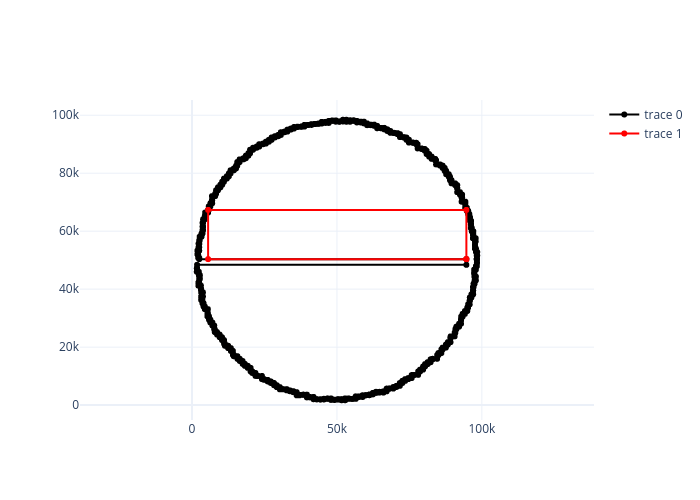

In [ ]:
# Kaleido 0.2.1 (pinned, as kaleido 1.x needs Chrome) raises a deprecation warning here.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    figure_png_9_2 = figure_9_2.to_image(format="png")

encoded_figure_9_2 = base64.b64encode(figure_png_9_2).decode()

mo.md(f"![Largest rectangle](data:image/png;base64,{encoded_figure_9_2})")